### 0. Описание задачи
Построить модель машинного обучения, которая сможет предсказать популярность песни

### 1. Прочитать данные

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/data/')

df = pd.read_csv('/data/MyDrive/dataset.csv')

display(df.head())

Drive already mounted at /data/; to attempt to forcibly remount, call drive.mount("/data/", force_remount=True).


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
print("Размер датасета:", df.shape)

print("\nИнформация о данных:")
df.info()

print("\nНазвания столбцов:")
print(df.columns.tolist())

Размер датасета: (114000, 21)

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness

### 2. Разбить данные на обучающую и тестовую выборки

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df, groups=df["track_id"])
)

train_full = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    val_splitter.split(
        train_full,
        groups=train_full["track_id"]
    )
)

train_df = train_full.iloc[train_idx].copy()
val_df = train_full.iloc[val_idx].copy()

print("Обучающая выборка:", train_df.shape)
print("Валидационная выборка:", val_df.shape)
print("Тестовая выборка:", test_df.shape)

print(
    "Совпадений композиций между обучением и тестом:",
    len(set(train_full["track_id"]) & set(test_df["track_id"]))
)

print(
    "Совпадений композиций между обучением и валидацией:",
    len(set(train_df["track_id"]) & set(val_df["track_id"]))
)

Обучающая выборка: (73202, 21)
Валидационная выборка: (18121, 21)
Тестовая выборка: (22677, 21)
Совпадений композиций между обучением и тестом: 0
Совпадений композиций между обучением и валидацией: 0


### 3: визуализация данных, вычисление среднего, разброса, корреляционной матрицы и интерпретация результатов.

In [ ]:
numeric_columns = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

display(
    train_df[numeric_columns].describe().T.round(2)
)

,count,mean,std,min,25%,50%,75%,max
popularity,73202.0,33.26,22.39,0.00,17.00,35.00,50.00,100.00
duration_ms,73202.0,227890.33,104608.78,0.00,174194.25,212900.50,261369.50,4730302.00
danceability,73202.0,0.57,0.17,0.00,0.46,0.58,0.70,0.98
energy,73202.0,0.64,0.25,0.00,0.47,0.68,0.85,1.00
loudness,73202.0,-8.27,5.04,-49.31,-10.02,-7.00,-5.00,4.53
speechiness,73202.0,0.08,0.11,0.00,0.04,0.05,0.08,0.96
acousticness,73202.0,0.31,0.33,0.00,0.02,0.17,0.60,1.00
instrumentalness,73202.0,0.16,0.31,0.00,0.00,0.00,0.05,1.00
liveness,73202.0,0.21,0.19,0.01,0.10,0.13,0.28,1.00
valence,73202.0,0.47,0.26,0.00,0.26,0.46,0.68,1.00


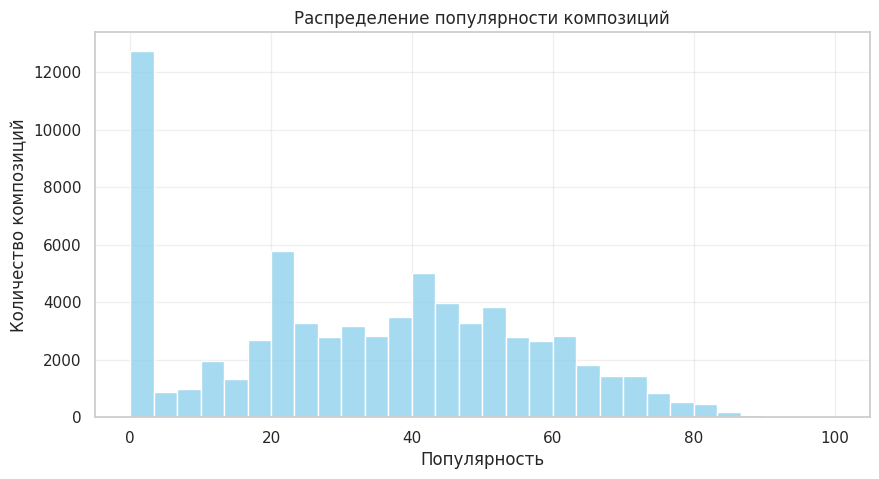

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["popularity"],
    bins=30,
    color="skyblue"
)

plt.title("Распределение популярности композиций")
plt.xlabel("Популярность")
plt.ylabel("Количество композиций")
plt.grid(alpha=0.3)

plt.show()

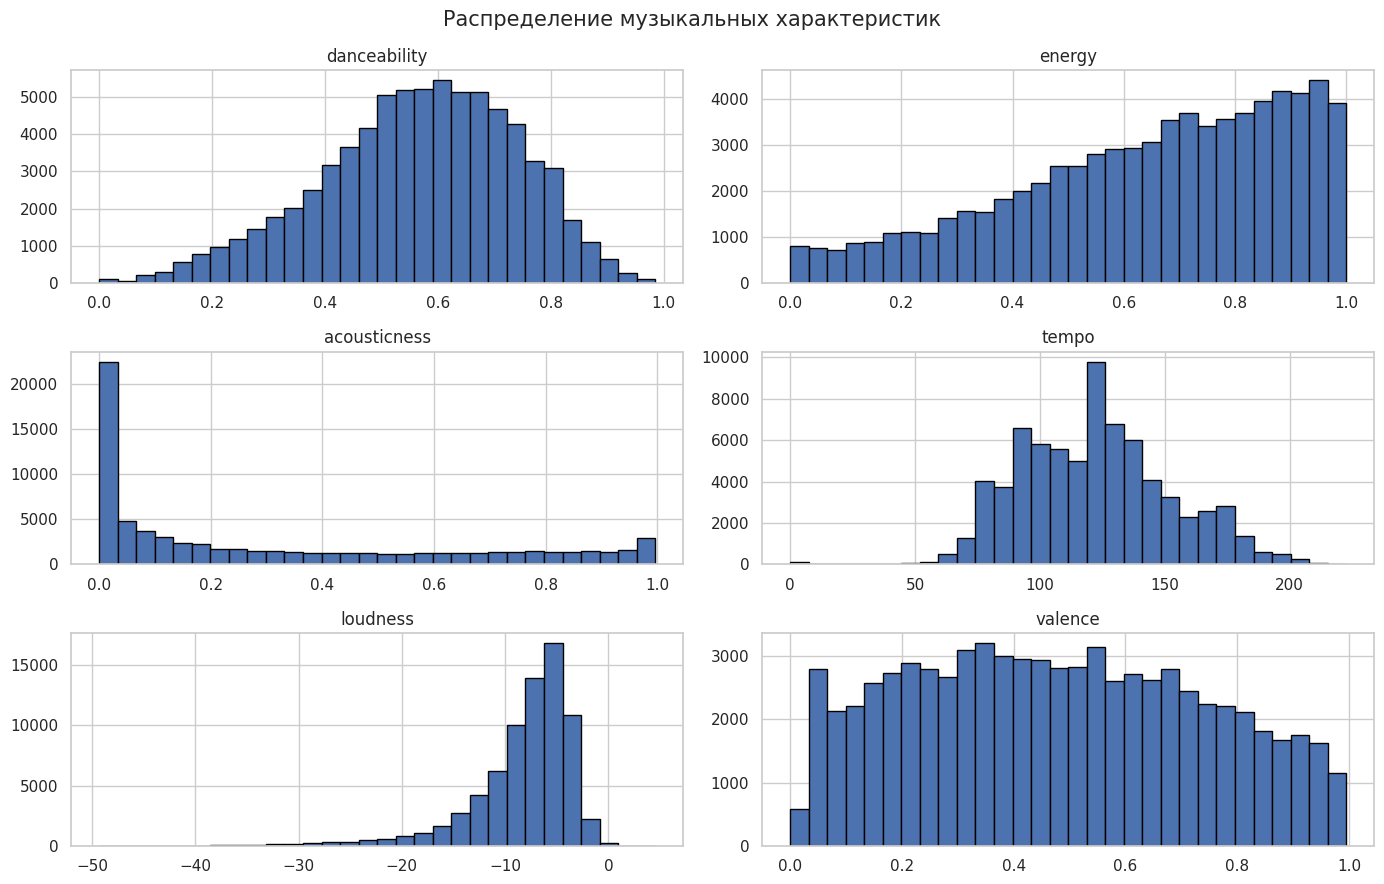

In [ ]:
columns = [
    "danceability",
    "energy",
    "acousticness",
    "tempo",
    "loudness",
    "valence"
]

train_df[columns].hist(
    figsize=(14, 9),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Распределение музыкальных характеристик",
    fontsize=15
)

plt.tight_layout()
plt.show()

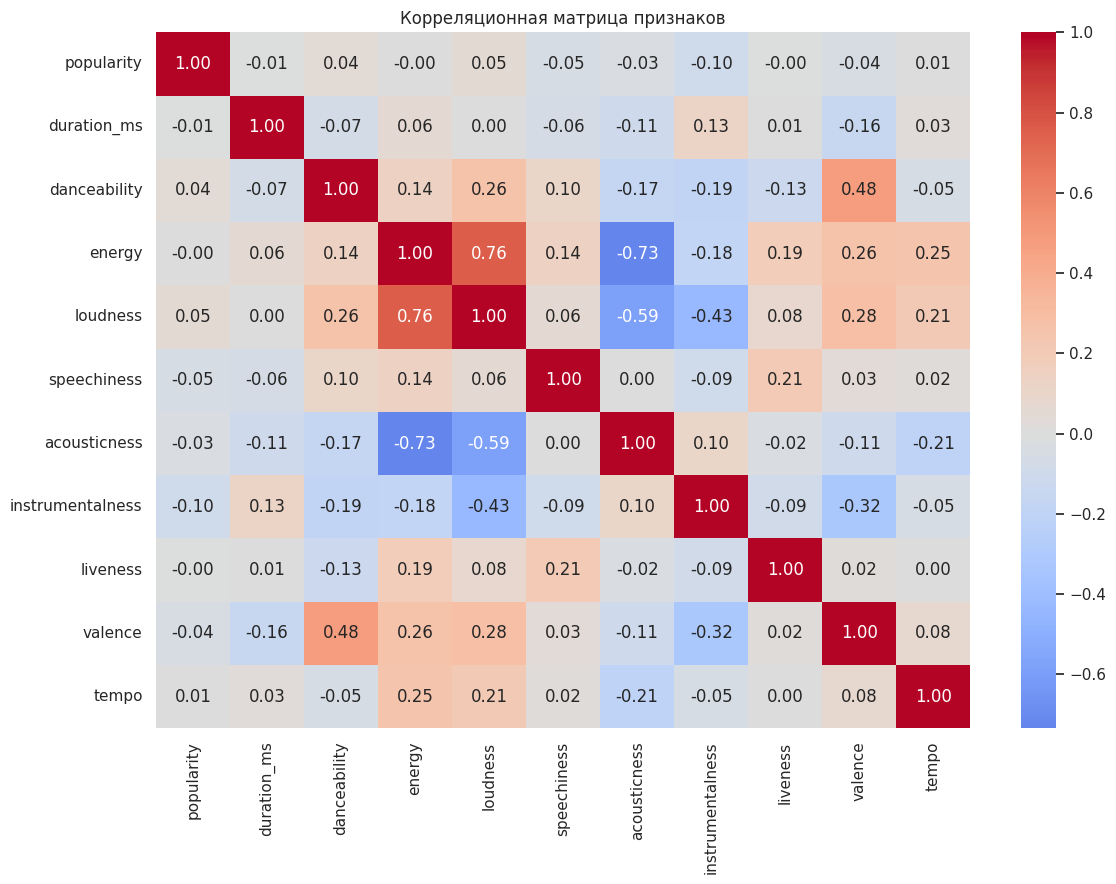

In [ ]:
correlation = train_df[numeric_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

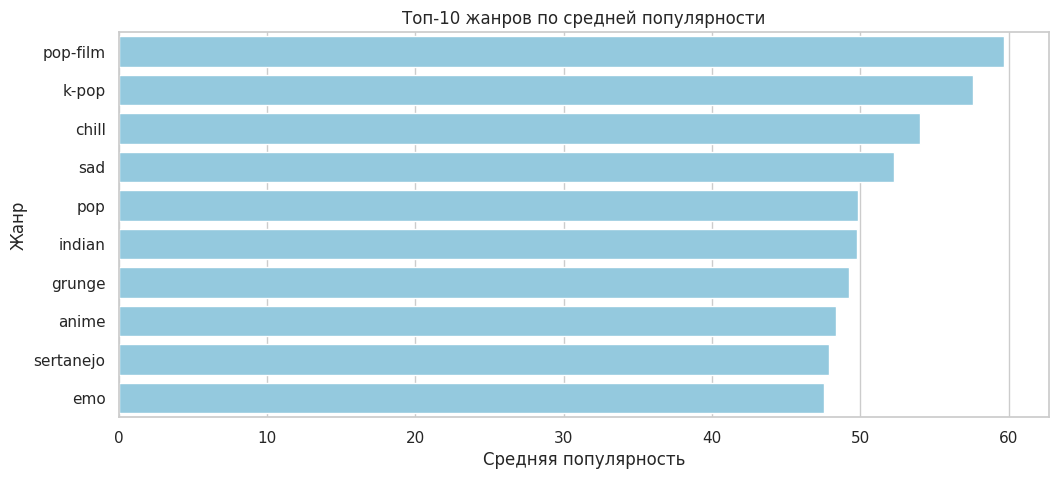

In [ ]:
genre_popularity = (
    train_df.groupby("track_genre")["popularity"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=genre_popularity.values,
    y=genre_popularity.index,
    color="skyblue"
)

plt.title("Топ-10 жанров по средней популярности")
plt.xlabel("Средняя популярность")
plt.ylabel("Жанр")

plt.show()

###4. Разобраться с выбросами

In [ ]:
Q1 = train_df["duration_ms"].quantile(0.25)
Q3 = train_df["duration_ms"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = train_df[
    (train_df["duration_ms"] < lower_bound) |
    (train_df["duration_ms"] > upper_bound)
]

print("Нижняя граница:", round(lower_bound, 2))
print("Верхняя граница:", round(upper_bound, 2))
print("Количество выбросов:", len(outliers))
print("Процент выбросов:", round(len(outliers) / len(train_df) * 100, 2))
print("Нулевая длительность:", (train_df["duration_ms"] == 0).sum())

Нижняя граница: 43431.38
Верхняя граница: 392132.38
Количество выбросов: 3638
Процент выбросов: 4.97
Нулевая длительность: 1


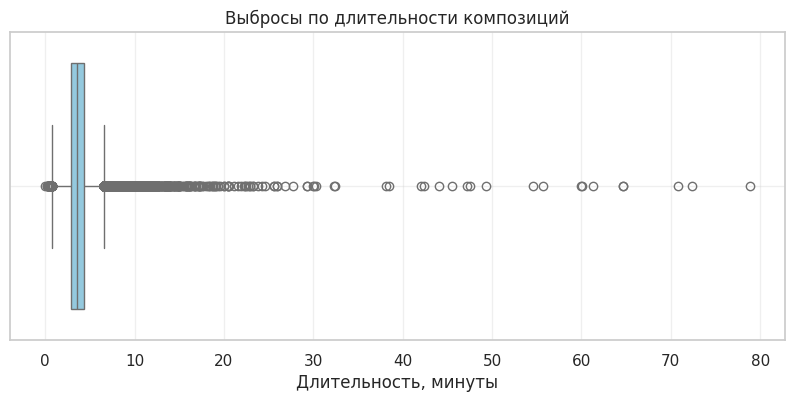

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=train_df["duration_ms"] / 60000,
    color="skyblue"
)

plt.title("Выбросы по длительности композиций")
plt.xlabel("Длительность, минуты")
plt.grid(alpha=0.3)

plt.show()

### 5. Обработать пропущенные значения

In [ ]:
missing = df.isnull().sum()

missing_percent = df.isnull().mean() * 100

missing_table = pd.DataFrame({
    "Количество пропусков": missing,
    "Процент пропусков": missing_percent
})

display(missing_table)

print("Всего пропущенных значений:", missing.sum())

,Количество пропусков,Процент пропусков
Unnamed: 0,0,0.000000
track_id,0,0.000000
artists,1,0.000877
album_name,1,0.000877
track_name,1,0.000877
popularity,0,0.000000
duration_ms,0,0.000000
explicit,0,0.000000
danceability,0,0.000000
energy,0,0.000000


Всего пропущенных значений: 3


In [ ]:
median_duration = train_df.loc[
    train_df["duration_ms"] > 0,
    "duration_ms"
].median()

for data in [train_df, val_df, test_df]:
    data["duration_ms"] = data["duration_ms"].replace(
        0, median_duration
    )

print("Медианная длительность:", median_duration)

print(
    "Нулевых длительностей после обработки:",
    (train_df["duration_ms"] == 0).sum()
)

Медианная длительность: 212904.0
Нулевых длительностей после обработки: 0


### 6. Обработать категориальные признаки

In [ ]:
categorical_features = [
    "track_genre",
    "key",
    "time_signature"
]

for data in [train_df, val_df, test_df]:
    for column in categorical_features:
        data[column] = data[column].astype(str)

    data["explicit"] = data["explicit"].astype(int)
    data["mode"] = data["mode"].astype(int)

display(
    train_df[
        categorical_features + ["explicit", "mode"]
    ].head()
)

,track_genre,key,time_signature,explicit,mode
1,acoustic,1,4,0,1
2,acoustic,0,4,0,1
5,acoustic,6,4,0,1
6,acoustic,2,3,0,1
10,acoustic,8,4,0,1


In [ ]:
print("Типы категориальных признаков:")
print(train_df[categorical_features].dtypes)

print("\nКоличество уникальных категорий:")
print(train_df[categorical_features].nunique())

print("\nРаспределение explicit:")
print(train_df["explicit"].value_counts())

Типы категориальных признаков:
track_genre       object
key               object
time_signature    object
dtype: object

Количество уникальных категорий:
track_genre       114
key                12
time_signature      5
dtype: int64

Распределение explicit:
explicit
0    66829
1     6373
Name: count, dtype: int64


###7. Провести нормализацию данных

In [ ]:
numeric_features = [
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

display(
    train_df[numeric_features].agg(["min", "max"]).T
)

,min,max
duration_ms,8586.00000,4730302.000
danceability,0.00000,0.985
energy,0.00002,1.000
loudness,-49.30700,4.532
speechiness,0.00000,0.965
acousticness,0.00000,0.996
instrumentalness,0.00000,1.000
liveness,0.00925,1.000
valence,0.00000,0.995
tempo,0.00000,222.605


### 8. Обучить модель CatBoostRegressor и подобрать оптимальное значение гиперпараметра.

In [ ]:
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 16.7 MB/s  0:00:05


In [ ]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = numeric_features + categorical_features + ["explicit", "mode"]

X_train = train_df[features]
y_train = train_df["popularity"]

X_val = val_df[features]
y_val = val_df["popularity"]

print("Размер обучающей выборки:", X_train.shape)
print("Размер валидационной выборки:", X_val.shape)

Размер обучающей выборки: (73202, 15)
Размер валидационной выборки: (18121, 15)


In [ ]:
depth_values = [4, 6, 8, 10]

results = []

for depth in depth_values:

    model = CatBoostRegressor(
        iterations=600,
        depth=depth,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features
    )

    y_pred = model.predict(X_val)

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    results.append({
        "depth": depth,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

best_depth = results_df.loc[
    results_df["MAE"].idxmin(), "depth"
]

print("Оптимальная глубина:", best_depth)

,depth,MAE,RMSE,R2
0,4,13.7835,18.6696,0.2885
1,6,13.4519,18.3119,0.3155
2,8,13.1420,17.9673,0.3410
3,10,12.7728,17.5918,0.3682


Оптимальная глубина: 10


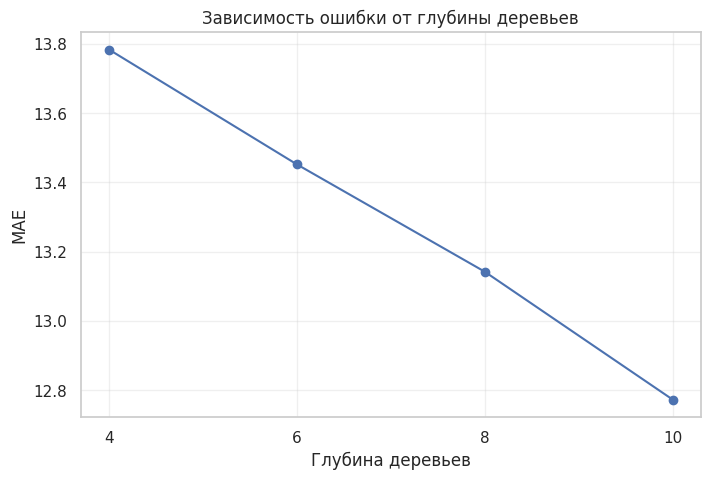

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["depth"],
    results_df["MAE"],
    marker="o"
)

plt.xlabel("Глубина деревьев")
plt.ylabel("MAE")
plt.title("Зависимость ошибки от глубины деревьев")

plt.xticks(depth_values)
plt.grid(alpha=0.3)

plt.show()

In [ ]:
best_model = CatBoostRegressor(
    iterations=600,
    depth=int(best_depth),
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

best_model.fit(
    X_train,
    y_train,
    cat_features=categorical_features
)

print("Модель успешно обучена")
print("Оптимальная глубина:", best_depth)

Модель успешно обучена
Оптимальная глубина: 10


### 9. Вычислить ошибки на обучающей и тестовой выборках

In [ ]:
X_test = test_df[features]
y_test = test_df["popularity"]

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

print("Количество предсказаний на обучении:", len(y_train_pred))
print("Количество предсказаний на тесте:", len(y_test_pred))

Количество предсказаний на обучении: 73202
Количество предсказаний на тесте: 22677


In [70]:
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

metrics = pd.DataFrame({
    "Выборка": ["Обучающая", "Тестовая"],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse],
    "R2": [train_r2, test_r2]
})

display(metrics.round(4))

,Выборка,MAE,RMSE,R2
0,Обучающая,10.7611,14.8062,0.5626
1,Тестовая,12.7566,17.5560,0.3734


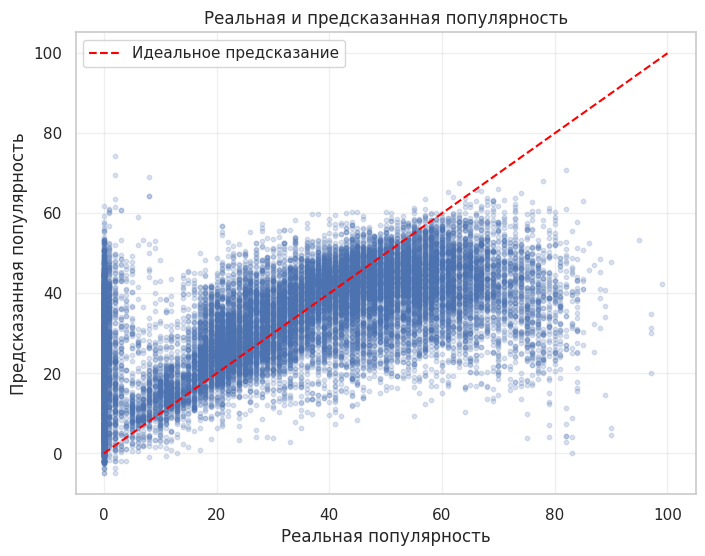

In [71]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.2,
    s=10
)

plt.plot(
    [0, 100],
    [0, 100],
    color="red",
    linestyle="--",
    label="Идеальное предсказание"
)

plt.xlabel("Реальная популярность")
plt.ylabel("Предсказанная популярность")
plt.title("Реальная и предсказанная популярность")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

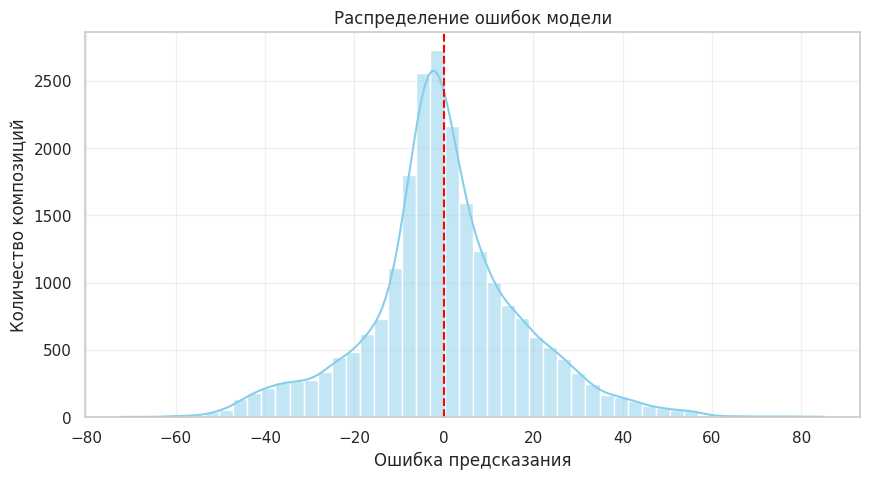

Средняя ошибка: -0.05
Стандартное отклонение ошибок: 17.56


In [72]:
errors = y_test.to_numpy() - y_test_pred

plt.figure(figsize=(10, 5))

sns.histplot(
    errors,
    bins=50,
    kde=True,
    color="skyblue"
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Ошибка предсказания")
plt.ylabel("Количество композиций")
plt.title("Распределение ошибок модели")
plt.grid(alpha=0.3)

plt.show()

print("Средняя ошибка:", round(errors.mean(), 2))
print("Стандартное отклонение ошибок:", round(errors.std(), 2))

In [73]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

comparison = pd.DataFrame({
    "Модель": ["Среднее значение", "CatBoost"],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        test_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        test_rmse
    ],
    "R2": [
        r2_score(y_test, baseline_pred),
        test_r2
    ]
})

display(comparison.round(4))

,Модель,MAE,RMSE,R2
0,Среднее значение,18.7909,22.178,-0.0000
1,CatBoost,12.7566,17.556,0.3734


### 10.Общие выводы

В ходе выполнения работы была построена модель машинного обучения для предсказания популярности музыкальных композиций на основе датасета Spotify Tracks Dataset, содержащего 114 000 записей.

Был проведён предварительный анализ данных: изучены основные статистические характеристики, построены графики распределения признаков и корреляционная матрица. Также были исследованы выбросы, проверено наличие пропущенных значений и выполнена обработка категориальных признаков.

Для решения задачи регрессии был выбран алгоритм **CatBoostRegressor**, основанный на градиентном бустинге над деревьями решений. Данный алгоритм позволяет учитывать числовые и категориальные признаки и выявлять нелинейные зависимости между характеристиками музыкальных композиций и их популярностью.

В процессе обучения был выполнен подбор оптимальной глубины деревьев на валидационной выборке.

**На тестовой выборке получены следующие результаты:**

- **MAE = 12,7566** - средняя абсолютная ошибка предсказания составляет около 12,76 балла популярности по шкале от 0 до 100.
- **RMSE = 17,5560** - среднеквадратичная ошибка, учитывающая более крупные отклонения предсказаний от реальных значений.
- **R² = 0,3734** - модель объясняет примерно 37,34% изменчивости популярности музыкальных композиций.

Сравнение результатов на обучающей и тестовой выборках показало наличие умеренного переобучения, поскольку на обучающих данных модель демонстрирует более высокое качество.

Полученные результаты свидетельствуют о том, что музыкальные характеристики и жанр композиции содержат информацию, полезную для предсказания популярности. Однако значительная часть изменчивости популярности остаётся необъяснённой. Это может быть связано с влиянием факторов, не представленных в датасете, например известности исполнителя, продвижения композиции и музыкальных тенденций.

Таким образом, построена и оценена модель CatBoostRegressor, позволяющая прогнозировать популярность музыкальных композиций по их характеристикам. Модель выявляет закономерности в данных, однако её предсказательная способность остаётся ограниченной.